In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project directories
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Load the processed reviews
reviews = pd.read_csv(PROCESSED_DIR / "reviews.csv")

print("Dataset shape:", reviews.shape)
print("\nColumns:")
print(reviews.columns.tolist())

print("\nFirst 5 rows:")
display(reviews.head())

print("\nData types:")
print(reviews.dtypes)

print("\nMissing values:")
print(reviews.isnull().sum())

print("\nDuplicate rows:", reviews.duplicated().sum())

Dataset shape: (2445, 4)

Columns:
['review_id', 'order_id', 'rating', 'review_text']

First 5 rows:


,review_id,order_id,rating,review_text
0,30001,12146,4,"Nice experience, would order again"
1,30002,12522,5,Excellent service and delicious food
2,30003,10665,5,"Amazing experience, very fast delivery"
3,30004,10540,3,"Average experience, nothing special"
4,30005,13299,5,Excellent service and delicious food



Data types:
review_id      int64
order_id       int64
rating         int64
review_text      str
dtype: object

Missing values:
review_id      0
order_id       0
rating         0
review_text    0
dtype: int64

Duplicate rows: 0


In [2]:
print(reviews.info())

# Inspect a few review examples
for i, row in reviews.head(5).iterrows():
    print("\nReview:", row.to_dict())

<class 'pandas.DataFrame'>
RangeIndex: 2445 entries, 0 to 2444
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    2445 non-null   int64
 1   order_id     2445 non-null   int64
 2   rating       2445 non-null   int64
 3   review_text  2445 non-null   str  
dtypes: int64(3), str(1)
memory usage: 76.5 KB
None

Review: {'review_id': 30001, 'order_id': 12146, 'rating': 4, 'review_text': 'Nice experience, would order again'}

Review: {'review_id': 30002, 'order_id': 12522, 'rating': 5, 'review_text': 'Excellent service and delicious food'}

Review: {'review_id': 30003, 'order_id': 10665, 'rating': 5, 'review_text': 'Amazing experience, very fast delivery'}

Review: {'review_id': 30004, 'order_id': 10540, 'rating': 3, 'review_text': 'Average experience, nothing special'}

Review: {'review_id': 30005, 'order_id': 13299, 'rating': 5, 'review_text': 'Excellent service and delicious food'}


In [3]:
# Rating distribution
print("Rating counts:")
print(reviews["rating"].value_counts().sort_index())

print("\nRating percentages:")
print(
    (reviews["rating"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Check missing values
print("\nMissing values:")
print(reviews.isnull().sum())

# Check duplicate review IDs
print("\nDuplicate review IDs:", reviews["review_id"].duplicated().sum())

# Check empty review text
print(
    "Empty review texts:",
    reviews["review_text"].fillna("").str.strip().eq("").sum()
)

Rating counts:
rating
1    170
2    218
3    437
4    857
5    763
Name: count, dtype: int64

Rating percentages:
rating
1     6.95
2     8.92
3    17.87
4    35.05
5    31.21
Name: proportion, dtype: float64

Missing values:
review_id      0
order_id       0
rating         0
review_text    0
dtype: int64

Duplicate review IDs: 0
Empty review texts: 0


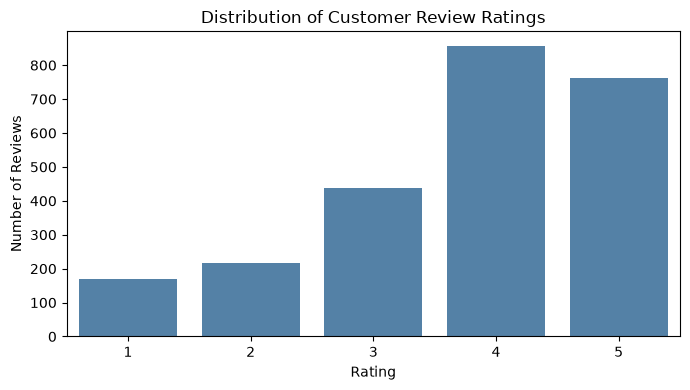

In [4]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=reviews,
    x="rating",
    color="steelblue"
)

plt.title("Distribution of Customer Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [5]:
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"


reviews["sentiment"] = reviews["rating"].apply(assign_sentiment)

print(reviews[["rating", "review_text", "sentiment"]].head(10))

print("\nSentiment distribution:")
print(reviews["sentiment"].value_counts())

   rating                                  review_text sentiment
0       4           Nice experience, would order again  Positive
1       5         Excellent service and delicious food  Positive
2       5       Amazing experience, very fast delivery  Positive
3       3          Average experience, nothing special   Neutral
4       5         Excellent service and delicious food  Positive
5       4           Nice experience, would order again  Positive
6       3          Average experience, nothing special   Neutral
7       1  Terrible experience, order arrived too late  Negative
8       4           Nice experience, would order again  Positive
9       3          Average experience, nothing special   Neutral

Sentiment distribution:
sentiment
Positive    1620
Neutral      437
Negative     388
Name: count, dtype: int64


In [6]:
import re

def clean_text(text):
    text = str(text).lower()          # Convert to lowercase
    text = re.sub(r"http\S+|www\S+", "", text)  # Remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)       # Keep letters and spaces
    text = re.sub(r"\s+", " ", text).strip()    # Normalize whitespace
    return text

reviews["cleaned_text"] = reviews["review_text"].apply(clean_text)

# Compare original and cleaned reviews
display(reviews[["review_text", "cleaned_text", "sentiment"]].head(10))

,review_text,cleaned_text,sentiment
0,"Nice experience, would order again",nice experience would order again,Positive
1,Excellent service and delicious food,excellent service and delicious food,Positive
2,"Amazing experience, very fast delivery",amazing experience very fast delivery,Positive
3,"Average experience, nothing special",average experience nothing special,Neutral
4,Excellent service and delicious food,excellent service and delicious food,Positive
5,"Nice experience, would order again",nice experience would order again,Positive
6,"Average experience, nothing special",average experience nothing special,Neutral
7,"Terrible experience, order arrived too late",terrible experience order arrived too late,Negative
8,"Nice experience, would order again",nice experience would order again,Positive
9,"Average experience, nothing special",average experience nothing special,Neutral


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    reviews["cleaned_text"],
    reviews["sentiment"],
    test_size=0.2,
    random_state=42,
    stratify=reviews["sentiment"]
)

tfidf = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("TF-IDF features:", X_train.shape[1])

Training samples: 1956
Testing samples: 489
TF-IDF features: 80


In [8]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

y_pred = nb_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
))

Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        78
     Neutral       1.00      1.00      1.00        87
    Positive       1.00      1.00      1.00       324

    accuracy                           1.00       489
   macro avg       1.00      1.00      1.00       489
weighted avg       1.00      1.00      1.00       489


Confusion matrix:
[[ 78   0   0]
 [  0  87   0]
 [  0   0 324]]


In [9]:
# Count repeated review texts
print("Unique review texts:", reviews["cleaned_text"].nunique())
print("Total reviews:", len(reviews))

print("\nMost common review texts:")
print(reviews["cleaned_text"].value_counts().head(10))

# Check whether each repeated text has the same sentiment
text_sentiment_check = (
    reviews.groupby("cleaned_text")["sentiment"]
    .nunique()
)

print(
    "\nReview texts associated with multiple sentiments:",
    (text_sentiment_check > 1).sum()
)

Unique review texts: 10
Total reviews: 2445

Most common review texts:
cleaned_text
good food and quick delivery                  455
nice experience would order again             402
amazing experience very fast delivery         400
excellent service and delicious food          363
average experience nothing special            233
food was okay but delivery could improve      204
delivery was slow and food was not great      114
not satisfied with the service                104
very late delivery and cold food               91
terrible experience order arrived too late     79
Name: count, dtype: int64

Review texts associated with multiple sentiments: 0


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_pred), 3))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

Logistic Regression Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        78
     Neutral       1.00      1.00      1.00        87
    Positive       1.00      1.00      1.00       324

    accuracy                           1.00       489
   macro avg       1.00      1.00      1.00       489
weighted avg       1.00      1.00      1.00       489



In [11]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, classification_report

analyzer = SentimentIntensityAnalyzer()

def vader_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews["vader_sentiment"] = reviews["review_text"].apply(vader_sentiment)

print("VADER accuracy:",
      round(accuracy_score(reviews["sentiment"],
                           reviews["vader_sentiment"]), 3))

print("\nClassification report:")
print(classification_report(
    reviews["sentiment"],
    reviews["vader_sentiment"],
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

VADER accuracy: 0.784

Classification report:
              precision    recall  f1-score   support

    Negative       0.56      0.77      0.65       388
     Neutral       0.00      0.00      0.00       437
    Positive       0.89      1.00      0.94      1620

    accuracy                           0.78      2445
   macro avg       0.48      0.59      0.53      2445
weighted avg       0.68      0.78      0.73      2445



### VADER Sentiment Analysis — Observations, Transitions, and Conclusions

#### Observations
- VADER achieved an overall accuracy of **78.4%**.
- Positive sentiment had the strongest performance, with an F1-score of **0.94** and recall of **1.00**.
- Negative sentiment achieved an F1-score of **0.65**, with recall of **0.77**.
- Neutral sentiment had precision, recall, and F1-score of **0.00**, indicating that VADER failed to identify the neutral class correctly.
- Naive Bayes and Logistic Regression with TF-IDF achieved 100% accuracy. However, the dataset contains only 10 unique review-text templates, and the sentiment labels are derived from ratings.

#### Transitions
After evaluating machine-learning models, VADER was used as a rule-based baseline. Unlike the trained models, VADER relies on a sentiment lexicon and linguistic rules rather than learning patterns from the training data. The comparison highlighted differences in how the approaches handle positive, negative, and neutral language.

#### Conclusions
VADER provides a useful baseline for sentiment analysis but struggles with neutral and mildly mixed reviews in this dataset. Naive Bayes and Logistic Regression achieved perfect scores, but the repeated review templates make these results unsuitable as evidence of real-world generalization. A more realistic evaluation would use diverse customer-written reviews and independently validated sentiment labels. The results also demonstrate why accuracy alone is insufficient when evaluating a model across multiple sentiment classes.


In [12]:
# Display the reviews VADER misclassified
vader_errors = reviews[
    reviews["sentiment"] != reviews["vader_sentiment"]
][["review_text", "sentiment", "vader_sentiment"]]

print("Total misclassified reviews:", len(vader_errors))
display(vader_errors.head(15))

Total misclassified reviews: 528


,review_text,sentiment,vader_sentiment
3,"Average experience, nothing special",Neutral,Negative
6,"Average experience, nothing special",Neutral,Negative
9,"Average experience, nothing special",Neutral,Negative
10,"Average experience, nothing special",Neutral,Negative
12,Very late delivery and cold food,Negative,Neutral
39,"Average experience, nothing special",Neutral,Negative
40,"Average experience, nothing special",Neutral,Negative
45,"Average experience, nothing special",Neutral,Negative
59,Very late delivery and cold food,Negative,Neutral
61,Food was okay but delivery could improve,Neutral,Positive


In [13]:
# Actual versus predicted sentiment
print(pd.crosstab(
    reviews["sentiment"],
    reviews["vader_sentiment"],
    rownames=["Actual"],
    colnames=["VADER Predicted"]
))

VADER Predicted  Negative  Neutral  Positive
Actual                                      
Negative              297       91         0
Neutral               233        0       204
Positive                0        0      1620


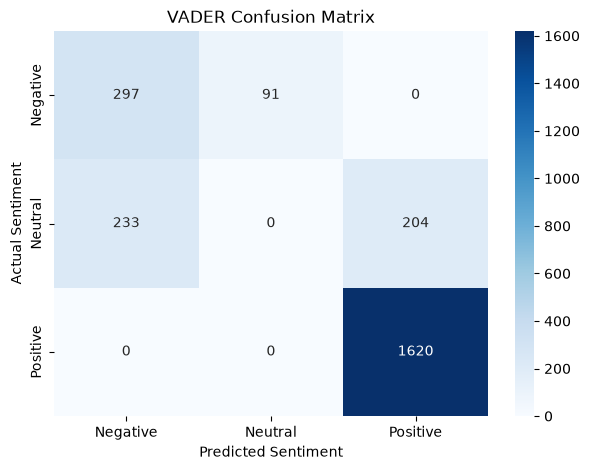

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    reviews["sentiment"],
    reviews["vader_sentiment"],
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("VADER Confusion Matrix")

plt.show()